# Projet Data Mining : dossier `health`

* Groupe : Groupe 10

Organisation. Ce notebook est le rapport court : il présente chaque découverte avec la méthode qui la montre. Le détail se trouve en annexe :
* [`01_nettoyage_health.ipynb`](01_nettoyage_health.ipynb) : tout le nettoyage, étape par étape ;
* [`02_analyse_health.ipynb`](02_analyse_health.ipynb) : l'analyse complète, cours par cours, y compris les méthodes qui n'ont rien apporté ;
* [`health_utils.py`](health_utils.py) : les fonctions de chargement et les calculs longs. Les choix de méthode (algorithmes, paramètres, seuils) restent visibles ici.

*Usage de l'IA générative : ce travail a été fait avec l'aide de Claude (Anthropic). L'assistant a écrit la plus grande partie du code et des textes, et a proposé des méthodes et des pistes d'interprétation. De notre côté, on a choisi les étapes, discuté et validé chaque décision de nettoyage et d'analyse, relu les résultats, et demandé des corrections quand un chiffre ou une interprétation ne tenait pas.*

## Résumé

On trouve dans le dossier `health` deux phénomènes, qui ne touchent jamais les mêmes patients.

1. Un programme de rajeunissement réservé à des dirigeants. 8 dirigeants reçoivent depuis 2014 des injections répétées de `MRP-42`, toutes faites par le même médecin. Chacune des 3 premières doses fait baisser leur âge biologique d'environ 3,5 ans. Les lots sont réservés dans l'ordre de la hiérarchie, et le lot n° 1 manque. La « recherche » sur des patients ordinaires arrive après coup et n'a aucun effet. 9 autres patients rajeunissent de la même façon, sans aucune injection enregistrée. Enfin, les consultations du 20 juin 2025 ont probablement été inventées.
2. Dix patients aux mesures physiques très inhabituelles. Ils ont deux rythmes cardiaques indépendants, des yeux qui bougent séparément et une identité instable à la caméra. Leurs notes officielles minimisent tout. L'un d'eux est relié à une personnalité publique, « Elias Voss ».

En croisant avec les autres dossiers (partie 7), les deux phénomènes se rejoignent : chaque injection des dirigeants correspond à une sortie de stock le même jour, et le produit arrive à la clinique par Meridian BioLogistics, l'entreprise présidée par Elias Voss.

## 0. Données et nettoyage

Les 7 fichiers du dossier sont utilisés. Le nettoyage (annexe 01) corrige les doublons, les écritures incohérentes, les dates et les nombres mal formatés, et retire les colonnes constantes. Les valeurs extrêmes sont marquées mais gardées, car ce sont justement elles qu'on cherche.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import health_utils as hu

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

tables = hu.charger()
P, E, PR, CR, SIG, N = tables["P"], tables["E"], tables["PR"], tables["CR"], tables["SIG"], tables["N"]
MEDICAL = tables["MEDICAL"]
occ = P.set_index("patient_number")["occupation_text"]
W2, feat = hu.variables_patient(tables)

display(tables["tailles"])
display(hu.resume_nettoyage(tables["JOURNAL"]))
print("variables construites par patient :", feat.shape)

,lignes,colonnes
patient_administration,240,12
clinical_encounters,1067,12
clinical_observations,17734,12
clinical_procedures,310,12
cardiac_recordings,44,15
cardiac_signal_samples,96925,4
clinical_notes,30,10


,lignes_concernées,fichiers
operation,,
doublon exact supprimé,6,"patient_administration, clinical_encounters, c..."
espaces en trop,57,"patient_administration, clinical_encounters, c..."
majuscules,96,"patient_administration, clinical_encounters, c..."
écriture majoritaire,1,patient_administration
null/NA/N/A -> manquant,59,"clinical_encounters, clinical_observations, cl..."
date remise au format standard,15,"patient_administration, clinical_encounters, c..."
virgule remplacée par un point,180,clinical_observations
unité collée retirée,160,clinical_observations
colonne constante supprimée,18206,"clinical_observations, clinical_procedures, ca..."


variables construites par patient : (240, 89)


## 1. Deux groupes de patients ressortent tout seuls

Question : existe-t-il des patients qui ne ressemblent pas aux autres, sans qu'on dise aux algorithmes qui chercher ?

Méthode. On a construit près de 90 variables par patient à partir de tous les fichiers : médiane, variabilité et évolution de chaque mesure, comptages d'anomalies, consultations, actes, ECG et notes.
* Cours 1 : corrélations de Pearson et de Spearman sur toutes les paires (environ 3 700).
* Cours 2 : regroupement sur les 27 mesures médicales standardisées (PCA, classification hiérarchique, DBSCAN). Les actes et la profession ne sont pas utilisés pour former les groupes, seulement pour les interpréter.

In [2]:
balayage = hu.balayage_correlations(feat.drop(columns="NB_MRP42"))
display(balayage.sort_values("spearman", key=abs, ascending=False).head(8).round(2))

,variable 1,variable 2,pearson,spearman,écart
181,BIOAGE,AGE,0.95,0.95,-0.00
3303,BINOCOORD_ATYP,CONSULT_ocular_assessment,0.67,0.81,-0.14
3636,CONSULT_research_procedure,ACTE_MRP-42,0.33,0.80,-0.47
3359,N_DISCORDANT,CONSULT_cardiac_assessment,0.69,0.75,-0.07
8,APICAL,PPULSE,0.76,0.75,0.00
3331,VESTIB_ANORMAL,CONSULT_mobility_assessment,0.89,0.72,0.17
618,MOBILITY,WALKSPD,0.73,0.71,0.02
1429,BIOAGE_STD,NB_CONSULT,0.68,0.69,-0.01


À part les liens attendus (âge biologique et âge réel, pouls au cœur et au poignet), deux signaux ressortent :
* les anomalies vont avec des examens ciblés : coordination des yeux atypique et bilans oculaires, pouls discordants et bilans cardiaques ;
* les consultations « recherche » vont avec l'acte `MRP-42`, et les chutes brutales d'âge biologique avec les « executive health reviews » (détail dans l'annexe 02, partie 1.6).

In [3]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import AgglomerativeClustering, DBSCAN, KMeans
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors

Z = StandardScaler().fit_transform(feat[MEDICAL].fillna(feat[MEDICAL].median()))
pca = PCA().fit(Z)
print("PCA - variables qui portent l'axe 1 :", list(pd.Series(abs(pca.components_[0]), MEDICAL).nlargest(5).index))

hier = AgglomerativeClustering(2, linkage="average").fit_predict(Z)
dist5 = np.sort(NearestNeighbors(n_neighbors=5).fit(Z).kneighbors(Z)[0][:, -1])
hors_groupe = DBSCAN(eps=np.quantile(dist5, .9), min_samples=5).fit_predict(Z) == -1
print(f"hiérarchique average k=2 : silhouette {silhouette_score(Z, hier):.2f}, petit groupe de {np.bincount(hier).min()} patients")
print("DBSCAN (eps = 90e percentile des distances au 5e voisin) :", hors_groupe.sum(), "patients hors groupe")

petit = (hier != np.bincount(hier).argmax()) & hors_groupe
display(feat.loc[petit, ["ECART_POULS", "THORPEAK", "LATSWAY", "IDCONS", "CAMMATCH", "N_DISCORDANT", "N_OCULAR_ATYP"]]
        .round(1).join(occ))

PCA - variables qui portent l'axe 1 : ['ECART_POULS', 'IDCONS', 'THORPEAK', 'THORVIB', 'CAMMATCH']
hiérarchique average k=2 : silhouette 0.24, petit groupe de 13 patients
DBSCAN (eps = 90e percentile des distances au 5e voisin) : 15 patients hors groupe


,ECART_POULS,THORPEAK,LATSWAY,IDCONS,CAMMATCH,N_DISCORDANT,N_OCULAR_ATYP,occupation_text
patient_number,,,,,,,,
PAT-31012,16.2,53.6,46.3,85.3,55.0,3.0,3.0,research professional
PAT-31037,27.0,44.6,74.2,66.7,68.0,5.0,4.0,research professional
PAT-31040,19.9,59.9,77.2,71.1,80.8,5.0,0.0,research professional
PAT-31065,29.8,55.5,58.0,91.3,74.1,6.0,5.0,clinical specialist
PAT-31086,27.2,80.7,54.8,76.2,59.2,6.0,0.0,corporate adviser
PAT-31115,14.5,51.2,70.2,71.7,72.2,3.0,2.0,clinical specialist
PAT-31162,15.7,68.2,60.0,68.6,73.7,3.0,4.0,corporate adviser
PAT-31186,24.1,65.9,50.3,96.7,81.9,5.0,4.0,corporate adviser
PAT-31215,26.3,55.1,67.6,78.2,82.6,6.0,0.0,research professional


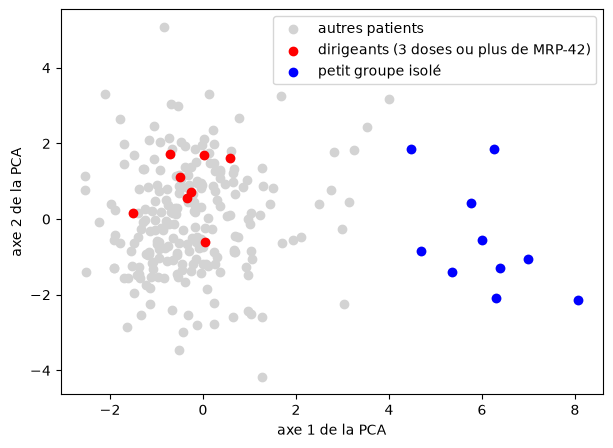

In [4]:
coords = pca.transform(Z)
dirigeants = (feat["NB_MRP42"] >= 3).values
plt.figure(figsize=(7, 5))
plt.scatter(coords[:, 0], coords[:, 1], color="lightgrey", label="autres patients")
plt.scatter(coords[dirigeants, 0], coords[dirigeants, 1], color="red", label="dirigeants (3 doses ou plus de MRP-42)")
plt.scatter(coords[petit, 0], coords[petit, 1], color="blue", label="petit groupe isolé")
plt.xlabel("axe 1 de la PCA")
plt.ylabel("axe 2 de la PCA")
plt.legend()
plt.show()

Sur le graphique, le petit groupe (en bleu) est nettement à l'écart du nuage, alors que les dirigeants (en rouge) sont mélangés aux autres patients. L'axe 1 de la PCA rassemble exactement les anomalies du cours 1. La classification hiérarchique et DBSCAN isolent les mêmes 10 patients. Ils ont un grand écart de pouls, un pic thoracique et un balancement élevés, une identité ou une caméra souvent basses, et de nombreux pouls « discordants », alors que ces comptages ne servaient pas au regroupement. Ils ont tous une profession discrète : `research professional`, `corporate adviser` ou `clinical specialist`. Les silhouettes restent faibles, car le reste des patients forme un seul nuage. La comparaison de toutes les méthodes (k-means, 3 liaisons, 6 réglages de DBSCAN, t-SNE) est dans l'annexe 02, partie 2.3.

Les dirigeants ne se distinguent que par leur âge. On refait donc un regroupement sur les seules variables de vieillissement.

In [5]:
AGE_VARS = ["ECART_AGE", "BIOAGE_PENTE", "CHUTE_MAX_AGE"]
Z_age = StandardScaler().fit_transform(feat[AGE_VARS].fillna(feat[AGE_VARS].median()))
km = KMeans(2, n_init=20, random_state=0).fit_predict(Z_age)
print(f"k-means k=2 sur le vieillissement : silhouette {silhouette_score(Z_age, km):.2f}")
rajeunis = feat.index[km == np.bincount(km).argmin()]

grp = pd.Series("autre", index=feat.index)
grp[petit] = "PHENO"
grp[rajeunis] = "RAJEUNI_NON_DECLARE"
grp[feat["NB_MRP42"] >= 3] = "ELITE"
E["groupe"] = E["patient_number"].map(grp)
display(feat.groupby(grp)[["ECART_AGE", "BIOAGE_PENTE", "NB_MRP42"]].median().round(1).assign(patients=grp.value_counts()))

k-means k=2 sur le vieillissement : silhouette 0.79


,ECART_AGE,BIOAGE_PENTE,NB_MRP42,patients
ELITE,-11.7,-0.9,4.0,8
PHENO,-4.1,1.0,0.0,10
RAJEUNI_NON_DECLARE,-8.5,-0.5,0.0,9
autre,-0.7,1.0,0.0,213


La séparation est très nette (silhouette 0,79). Le petit groupe compte 17 patients rajeunis : les 8 dirigeants qui ont reçu au moins 3 doses de `MRP-42`, et 9 patients sans traitement répété enregistré. On obtient trois groupes, qui servent dans toute la suite :
* ELITE : les 8 dirigeants traités par `MRP-42` ;
* RAJEUNI_NON_DECLARE : les 9 rajeunis sans traitement enregistré ;
* PHENO : les 10 patients au profil physique atypique.

## 2. Le programme `MRP-42` de l'élite

Question : qui reçoit `MRP-42`, qui l'administre, selon quel rythme, et avec quel effet ?

Méthodes : co-occurrences (cours 3), communautés de Louvain et process mining (cours 4), effet avant/après chaque dose et chronologie (cours 5).

In [6]:
mrp = PR[PR["procedure_code"] == "MRP-42"].copy()
mrp["groupe"] = mrp["patient_number"].map(grp)
display(pd.crosstab([mrp["performing_license_number"], mrp["authorization_class"]], mrp["groupe"]))
display(feat.loc[grp == "ELITE", ["NB_MRP42", "AGE", "ECART_AGE", "BIOAGE_PENTE"]].round(1).join(occ).sort_values("ECART_AGE"))

groupe                                           ELITE  RAJEUNI_NON_DECLARE  autre
performing_license_number authorization_class                                     
LIC-VLN-MED-1001          research_restricted        0                    0      1
LIC-VLN-MED-1002          research_restricted        0                    1      5
                          restricted_specialist     30                    0      0
LIC-VLN-MED-1003          research_restricted        0                    0      1
LIC-VLN-MED-1004          research_restricted        0                    0      3
LIC-VLN-MED-1006          research_restricted        0                    0      4
LIC-VLN-RES-1016          research_restricted        0                    0      3
LIC-VLN-RES-1044          research_restricted        0                    0      2

,NB_MRP42,AGE,ECART_AGE,BIOAGE_PENTE,occupation_text
patient_number,,,,,
PAT-31119,4.0,69.8,-14.1,-0.9,Chief executive of Solvane Energy Group
PAT-31044,4.0,66.5,-12.5,0.3,Senior minister of the Avelora Federation
PAT-31074,4.0,73.6,-12.4,-0.9,Executive chair of Nivren Maritime Logistics
PAT-31183,3.0,60.3,-12.0,-0.9,Executive director of Ardena Capital Union
PAT-31174,4.0,75.7,-11.4,-0.2,Regional governor in the Tembara Commonwealth
PAT-31142,3.0,69.0,-10.9,-0.9,Chair of Belen Agro-Industries
PAT-31221,5.0,72.9,-10.6,0.2,Head of government of Kintara Republic
PAT-31099,3.0,80.9,-8.9,-1.0,Retired political intermediary and former coun...


* Les 30 doses des dirigeants (classe « specialist restricted ») sont toutes faites par `LIC-VLN-MED-1002`. Ce sont un chef de gouvernement, un ministre, un gouverneur, des PDG et un ancien intermédiaire politique.
* Leur âge biologique est 9 à 14 ans inférieur à leur âge réel. Pour 6 d'entre eux, il baisse avec le temps (pente médiane de −0,9 an par an), alors qu'il augmente de 1 an par an chez les autres patients.
* 20 patients ont reçu une seule dose, classée « research restricted ». L'un d'eux est un rajeuni non déclaré.

Est-ce que ça pourrait être le hasard ? On tire 10 000 fois 8 patients au hasard parmi les 240, et on calcule à chaque fois leur écart moyen entre âge biologique et âge réel. Si aucun tirage n'est aussi bas que les dirigeants, le hasard est écarté.

dirigeants : -11.6 ans
8 patients au hasard : -1.3 ans en moyenne, -7.3 au plus bas
part des tirages aussi bas que les dirigeants : 0.0


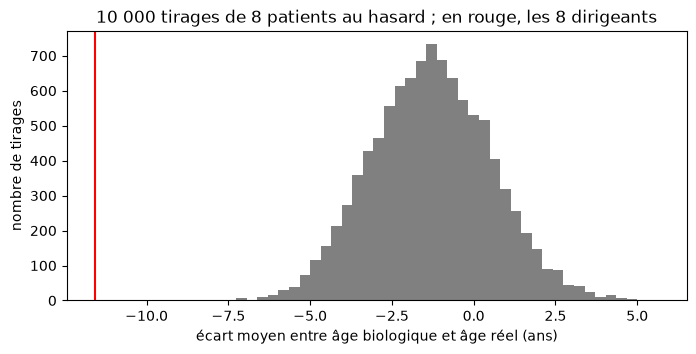

In [7]:
rng = np.random.default_rng(0)
observe = feat.loc[grp == "ELITE", "ECART_AGE"].mean()
hasard = []
for i in range(10000):
    tirage = rng.choice(feat["ECART_AGE"].values, size=8, replace=False)
    hasard.append(tirage.mean())
hasard = np.array(hasard)

print(f"dirigeants : {observe:.1f} ans")
print(f"8 patients au hasard : {hasard.mean():.1f} ans en moyenne, {hasard.min():.1f} au plus bas")
print("part des tirages aussi bas que les dirigeants :", (hasard <= observe).mean())

plt.figure(figsize=(8, 3.5))
plt.hist(hasard, bins=40, color="grey")
plt.axvline(observe, color="red")
plt.xlabel("écart moyen entre âge biologique et âge réel (ans)")
plt.ylabel("nombre de tirages")
plt.title("10 000 tirages de 8 patients au hasard ; en rouge, les 8 dirigeants")
plt.show()

Aucun des 10 000 tirages n'est aussi bas que les dirigeants : le hasard est écarté. Ce test montre que les dirigeants sont différents des autres patients, pas que c'est `MRP-42` qui les rajeunit. C'est l'effet mesuré dose par dose, plus bas, qui va dans ce sens.

On vérifie que ce médecin structure aussi le réseau. On relie deux patients s'ils sont suivis par les mêmes médecins, puis on cherche des communautés avec Louvain, en faisant varier le seuil et l'initialisation.

In [8]:
import networkx as nx
from networkx.algorithms import community as nxc

profil, simil = hu.similarite_medecins(E)
elite_ids = set(grp[grp == "ELITE"].index)
stab = []
for q in [.9, .95, .98]:
    G = hu.graphe_patients(profil, simil, q)
    for graine in [0, 1, 2]:
        comms = nxc.louvain_communities(G, weight="weight", seed=graine)
        c = max(comms, key=lambda c: len(c & elite_ids))
        stab.append({"seuil": q, "graine": graine, "modularité": round(nxc.modularity(G, comms, weight="weight"), 2),
                     "dirigeants dans la même communauté": len(c & elite_ids),
                     "médecin dominant": profil.loc[list(c)].mean().idxmax()})
display(pd.DataFrame(stab).groupby("seuil").agg(lambda s: sorted(set(s))))

,graine,modularité,dirigeants dans la même communauté,médecin dominant
seuil,,,,
0.90,"[0, 1, 2]","[0.45, 0.46]",[8],[LIC-VLN-MED-1002]
0.95,"[0, 1, 2]","[0.55, 0.56]",[8],[LIC-VLN-MED-1002]
0.98,"[0, 1, 2]",[0.65],[8],[LIC-VLN-MED-1002]


Dans les 9 essais, les 8 dirigeants sont toujours dans la même communauté, toujours organisée autour de `MED-1002`.

On reconstitue ensuite le parcours de chaque patient (consultations, actes, ECG dans l'ordre chronologique). On en tire les enchaînements les plus fréquents et le degré de dépendance de l'Heuristic Miner : proche de 1, il signifie que « A est presque toujours suivi de B, et jamais l'inverse ».

In [9]:
evenements, traces = hu.journal_evenements(E, PR, CR)
dfg = {g: hu.enchainements(traces[grp.reindex(traces.index) == g]) for g in ["ELITE", "RAJEUNI_NON_DECLARE", "PHENO"]}
display(pd.DataFrame({g: [f"{a} → {b} ({n})" for (a, b), n in c.most_common(4)] for g, c in dfg.items()}))
display(hu.dependances(traces).head(4).round(2).rename("dépendance").to_frame())

ev = evenements[evenements["patient"].isin(elite_ids)].copy()
ev["délai"] = ev.groupby("patient")["t"].shift(-1).sub(ev["t"]).dt.days
print("Délai entre une injection et l'étape suivante (jours) :",
      ev.loc[ev["etape"] == "acte MRP-42", "délai"].agg(["mean", "std"]).round(0).to_dict())

,ELITE,RAJEUNI_NON_DECLARE,PHENO
0,specialist_procedure → acte MRP-42 (30),executive_health_review → executive_health_rev...,DEBUT → cardiac_assessment (5)
1,executive_health_review → specialist_procedure...,DEBUT → executive_health_review (9),cardiac_assessment → cardiac_assessment (4)
2,acte MRP-42 → executive_health_review (26),executive_health_review → acte AGE-PNL (4),mobility_assessment → mobility_assessment (4)
3,DEBUT → executive_health_review (8),executive_health_review → FIN (4),cardiac_assessment → mobility_assessment (3)


,,dépendance
specialist_procedure,acte MRP-42,0.97
acte MRP-42,executive_health_review,0.96
executive_health_review,specialist_procedure,0.96
research_procedure,acte MRP-42,0.95


Délai entre une injection et l'étape suivante (jours) : {'mean': 35.0, 'std': 6.0}


Les dirigeants suivent un cycle très régulier : executive review, puis consultation « procédure », puis injection, puis executive review environ 35 jours plus tard (écart-type de 6 jours). Les dépendances de 0,96 à 0,97 confirment ce cycle.

Pour mesurer l'effet, on compare l'écart d'âge biologique à la visite juste avant et juste après chaque dose.

In [10]:
effets = hu.effet_doses(PR, W2)
display(effets.groupby(["classe", "rang de la dose"])["effet (années)"].agg(["mean", "min", "max", "count"]).round(1))

mean  min  max  count
classe                rang de la dose                       
research_restricted   1                 0.0 -0.0  0.0      8
restricted_specialist 1                -3.5 -5.7 -0.3      5
                      2                -3.6 -6.2 -0.9      8
                      3                -3.8 -6.5  1.3      8
                      4                -0.3 -4.6  3.0      5
                      5                 8.2  8.2  8.2      1

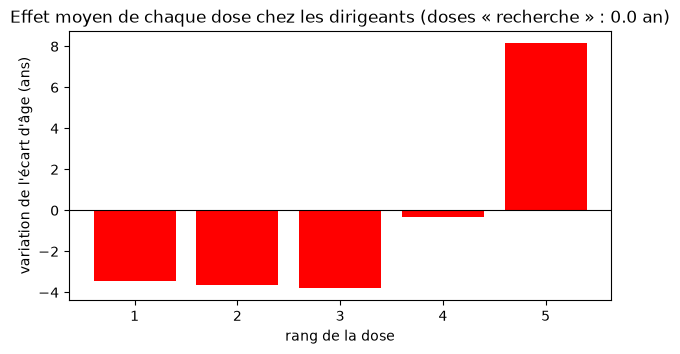

In [11]:
dirigeants_effet = effets[effets["classe"] == "restricted_specialist"].groupby("rang de la dose")["effet (années)"].mean()
recherche_effet = abs(effets.loc[effets["classe"] == "research_restricted", "effet (années)"].mean())
plt.figure(figsize=(7, 3.5))
plt.bar(dirigeants_effet.index, dirigeants_effet.values, color="red")
plt.axhline(0, color="black", linewidth=0.8)
plt.xlabel("rang de la dose")
plt.ylabel("variation de l'écart d'âge (ans)")
plt.title(f"Effet moyen de chaque dose chez les dirigeants (doses « recherche » : {recherche_effet:.1f} an)")
plt.show()

* Chacune des 3 premières doses rajeunit d'environ 3,5 ans : ce sont les trois barres sous zéro sur le graphique.
* À partir de la 4e, l'effet disparaît ou s'inverse. Le chef de gouvernement, le seul à avoir reçu une 5e dose, prend 8 ans après celle-ci en 2024.
* Les 20 doses « recherche » n'ont aucun effet (0,0 an).

Enfin, chaque injection porte un numéro de lot `MTL-année-numéro`.

In [12]:
lots, blocs = hu.lots_mrp42(PR, occ)
display(blocs)
display(lots.groupby("série")["numéro"].agg(["min", "max", "count"]))
display(pd.crosstab(mrp["authorization_class"], mrp["performed_time"].dt.year))

,lots,premier_lot,première_injection,occupation_text
patient_number,,,,
PAT-31221,2 à 6,2,2016-02-18,Head of government of Kintara Republic
PAT-31044,7 à 10,7,2017-05-12,Senior minister of the Avelora Federation
PAT-31174,11 à 14,11,2015-09-10,Regional governor in the Tembara Commonwealth
PAT-31119,15 à 18,15,2018-01-26,Chief executive of Solvane Energy Group
PAT-31074,19 à 22,19,2017-11-03,Executive chair of Nivren Maritime Logistics
PAT-31183,23 à 25,23,2016-06-16,Executive director of Ardena Capital Union
PAT-31142,26 à 28,26,2019-03-14,Chair of Belen Agro-Industries
PAT-31099,29 à 31,29,2014-07-18,Retired political intermediary and former coun...


,min,max,count
série,,,
dirigeants (MTL),2,31,30
recherche (MTL-R),32,51,20


performed_time,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
authorization_class,,,,,,,,,,,,
research_restricted,0,0,0,0,0,1,3,3,2,9,2,0
restricted_specialist,1,1,3,3,4,4,3,3,3,1,3,1


* Les lots 2 à 31 sont attribués par blocs à chaque dirigeant, dans l'ordre de la hiérarchie : chef de gouvernement, ministre, gouverneur, PDG, puis l'ancien intermédiaire. Ce n'est pas l'ordre chronologique : l'intermédiaire reçoit le lot 29 dès 2014, deux ans avant l'utilisation du lot 2. On peut penser que les doses ont été réservées à l'avance pour chaque dirigeant, mais c'est une hypothèse.
* Le lot n° 1 n'apparaît nulle part.
* La série « recherche » (`MTL-R`, lots 32 à 51) ne commence qu'en 2019, cinq ans après le début du programme. Ce n'est pas un essai préalable : elle arrive après coup et ressemble à une couverture.

## 3. Neuf patients rajeunis sans traitement déclaré

Question : les 9 rajeunis sans acte `MRP-42` ont-ils été traités en cachette ?

Méthodes : parcours de soins (cours 3 et 4), anomalies par rapport à l'historique du patient (cours 3), regroupement des trajectoires par DTW (cours 5).

In [13]:
display((pd.crosstab(E["groupe"], E["encounter_type"], normalize="index") * 100).round(0)
        [["executive_health_review", "specialist_procedure", "cardiac_assessment", "ocular_assessment"]])

ruptures = hu.ruptures_individuelles(W2, E, seuil=6)
ruptures["groupe"] = ruptures["patient"].map(grp)
display(ruptures.sort_values("z modifié").round(1))

encounter_type,executive_health_review,specialist_procedure,cardiac_assessment,ocular_assessment
groupe,,,,
ELITE,56.0,44.0,0.0,0.0
PHENO,0.0,0.0,29.0,22.0
RAJEUNI_NON_DECLARE,98.0,0.0,0.0,0.0
autre,2.0,0.0,7.0,4.0


,patient,consultation,écart âge,médiane du patient,z modifié,date,type,groupe
0,PAT-31011,ENC-000780,-17.8,-7.0,-14.7,2021-05-01,executive_health_review,RAJEUNI_NON_DECLARE
5,PAT-31122,ENC-000448,-19.1,-8.8,-13.8,2024-08-03,executive_health_review,RAJEUNI_NON_DECLARE
2,PAT-31046,ENC-000347,-18.0,-8.5,-12.8,2025-06-20,executive_health_review,RAJEUNI_NON_DECLARE
4,PAT-31110,ENC-000694,-15.9,-6.7,-12.3,2020-05-22,executive_health_review,RAJEUNI_NON_DECLARE
1,PAT-31017,ENC-000162,-13.9,-7.3,-8.9,2025-06-20,executive_health_review,RAJEUNI_NON_DECLARE
6,PAT-31179,ENC-000264,-13.5,-8.7,-6.4,2022-12-16,executive_health_review,RAJEUNI_NON_DECLARE
3,PAT-31071,ENC-000232,-13.6,-9.2,-6.0,2024-02-23,executive_health_review,RAJEUNI_NON_DECLARE


* Les rajeunis non déclarés n'ont que des executive reviews (98 % de leurs consultations), comme les dirigeants. En revanche, ils n'ont aucune consultation « procédure », alors que c'est là que les dirigeants reçoivent leurs doses. Leurs seuls actes sont des bilans (âge, autonomie, suivi oculaire…).
* Leur parcours est une simple boucle review → review (tableau des enchaînements de la partie 2) : c'est le cycle des dirigeants sans l'injection.
* On compare chaque visite à l'historique du même patient avec un z-score modifié. Sur les 240 patients, 7 ruptures dépassent le seuil (z de −6 à −15). Elles touchent toutes des rajeunis non déclarés (7 sur 9), toujours lors d'une executive review, et deux tombent le 20 juin 2025.

On compare enfin les trajectoires d'âge biologique avec le Dynamic Time Warping. Le DTW réaligne des séries de longueurs et de dates différentes. Chaque trajectoire est ramenée à 0 à la première visite, puis on fait une classification hiérarchique sur les distances.

In [14]:
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform

traj = hu.trajectoires(W2)
ids, dist = hu.matrice_dtw(traj)
groupes_dtw = fcluster(linkage(squareform(dist), "average"), 2, "maxclust")
display(pd.crosstab(pd.Series(groupes_dtw, index=ids, name="groupe DTW"), grp.reindex(ids).rename("groupe")))

groupe,ELITE,PHENO,RAJEUNI_NON_DECLARE,autre
groupe DTW,,,,
1,0,10,5,212
2,8,0,4,0


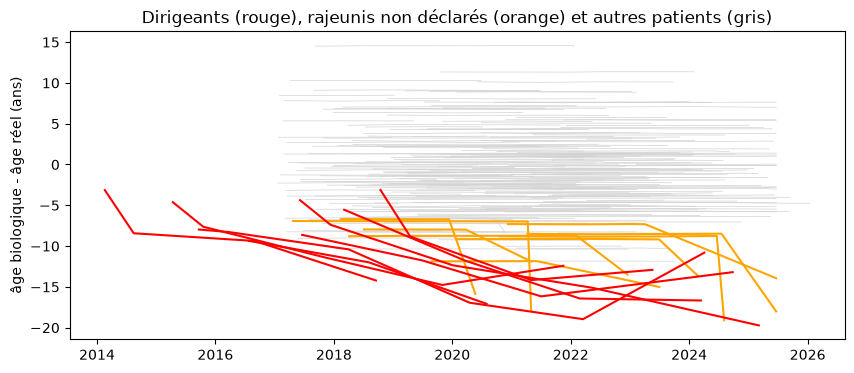

In [15]:
couleurs = {"ELITE": "red", "RAJEUNI_NON_DECLARE": "orange"}
avec_age = W2.dropna(subset=["ECART_AGE"])
fig, ax = plt.subplots(figsize=(10, 4))
for groupe in ["autre", "PHENO", "RAJEUNI_NON_DECLARE", "ELITE"]:   # les groupes colorés sont dessinés en dernier
    for patient in grp.index[grp == groupe]:
        d = avec_age[avec_age["patient_number"] == patient]
        ax.plot(d["encounter_start"], d["ECART_AGE"], color=couleurs.get(groupe, "lightgrey"),
                linewidth=1.5 if groupe in couleurs else 0.5)
ax.set_ylabel("âge biologique - âge réel (ans)")
ax.set_title("Dirigeants (rouge), rajeunis non déclarés (orange) et autres patients (gris)")
plt.show()

Sur le graphique, les dirigeants (en rouge) descendent peu à peu sous les autres patients ; les rajeunis non déclarés (en orange) restent stables puis chutent d'un coup. Le DTW isole un groupe pur de 12 trajectoires : les 8 dirigeants et 4 rajeunis non déclarés, sans aucun patient ordinaire. Ces patients ont la même évolution que les dirigeants traités. Ils ont probablement reçu des injections qui n'ont pas été enregistrées.

## 4. Le 20 juin 2025

Méthode : recherche des consultations d'un même médecin qui se chevauchent (anomalie contextuelle, cours 3).

In [16]:
chev = hu.consultations_simultanees(E)
display(chev.groupby("jour").agg(simultanées=("médecin", "size"), dans_deux_cliniques=("deux cliniques à la fois", "sum"))
        .sort_values("simultanées", ascending=False).head(3))
j20 = E[E["jour"] == "2025-06-20"]
deuxieme_jour = E["jour"].value_counts().iloc[1]
prevues = (pd.to_datetime(E["follow_up_date"]).dt.date.astype(str) == "2025-06-20").sum()
print("Consultations ce jour-là :", len(j20), "| autre jour le plus chargé :", deuxieme_jour,
      "| prévues à l'avance comme date de suivi :", prevues)

,simultanées,dans_deux_cliniques
jour,,
2025-06-20,25,11
2023-06-17,3,2
2018-07-21,1,1


Consultations ce jour-là : 22 | autre jour le plus chargé : 3 | prévues à l'avance comme date de suivi : 22


22 consultations ont lieu ce jour-là, contre 3 au plus n'importe quel autre jour. Elles ont toutes été fixées des mois à l'avance. Les médecins sont dans plusieurs consultations en même temps, parfois dans deux cliniques de deux pays différents (Valenne et Avelora), ce qui est impossible. Ces consultations ont probablement été inventées, et deux rajeunis non déclarés y « rajeunissent ». Cette date est à chercher dans les autres dossiers.

## 5. Dix patients aux mesures physiques inhabituelles

Question : les 10 patients PHENO ont-ils une vraie particularité physique, ou s'agit-il d'erreurs de mesure ?

Méthodes : anomalies multivariées (cours 3), signal cardiaque brut (cours 5), fouille des notes cliniques (cours 6).

In [17]:
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor

scores = pd.DataFrame({
    "Isolation Forest": -IsolationForest(n_estimators=500, random_state=0).fit(Z).score_samples(Z),
    "LOF": -LocalOutlierFactor(n_neighbors=20).fit(Z).negative_outlier_factor_,
    "ABOD": -np.log(hu.abod(Z)),
}, index=feat.index)
top15 = {}
for methode in scores.columns:
    plus_anormaux = scores[methode].nlargest(15).index
    top15[methode] = grp[plus_anormaux].value_counts()
print("Groupe des 15 patients les plus anormaux, pour chaque méthode :")
display(pd.DataFrame(top15).fillna(0).astype(int))

Groupe des 15 patients les plus anormaux, pour chaque méthode :


,Isolation Forest,LOF,ABOD
PHENO,8,8,9
autre,7,7,6


Les trois méthodes placent 8 ou 9 patients PHENO parmi leurs 15 patients les plus anormaux. Les notes parlent d'une « seconde source pulsatile ». On le vérifie sur les 44 ECG à deux canaux : on détecte les battements de chaque canal, puis on mesure la part de battements synchrones (moins de 50 ms d'écart).

In [18]:
ecg = hu.synchronie_ecg(CR, SIG, hauteur=.9, ecart_min_s=.3, tolerance_s=.05)
ecg["groupe"] = ecg["patient"].map(grp)
display(ecg.groupby("groupe")["battements synchrones"].agg(["mean", "min", "max", "count"]).round(2))
display((pd.crosstab(E["groupe"], E["facility_license_number"], normalize="index") * 100).round(0))

,mean,min,max,count
groupe,,,,
ELITE,1.00,0.98,1.00,4
PHENO,0.18,0.13,0.27,8
RAJEUNI_NON_DECLARE,1.00,1.00,1.00,1
autre,0.89,0.30,1.00,31


facility_license_number,FAC-AVL-201,FAC-AVL-301,FAC-VLN-101
groupe,,,
ELITE,47.0,0.0,53.0
PHENO,29.0,31.0,40.0
RAJEUNI_NON_DECLARE,33.0,11.0,57.0
autre,26.0,10.0,64.0


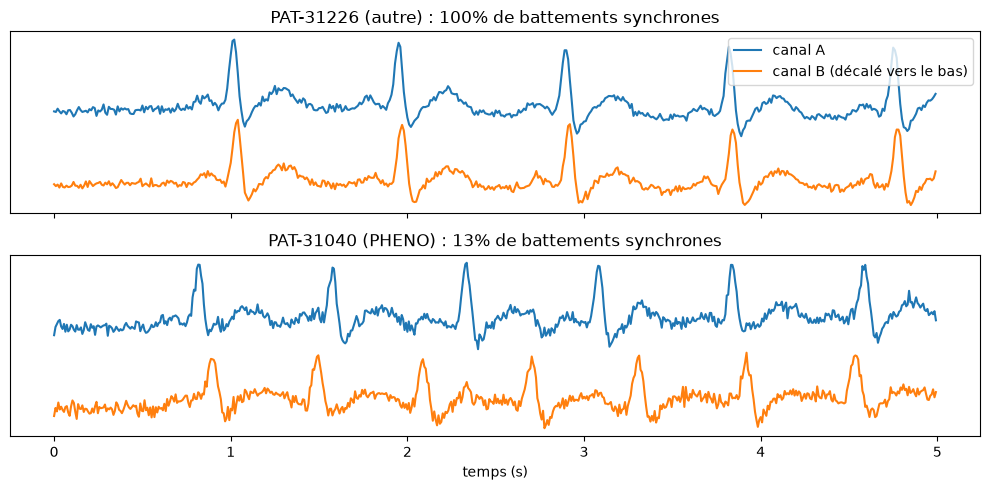

In [19]:
# un ECG ordinaire et l'ECG PHENO le moins synchrone, sur les 5 premières secondes
ordinaire = ecg[(ecg["groupe"] == "autre") & (ecg["battements synchrones"] == 1)].iloc[0]
pheno = ecg[ecg["groupe"] == "PHENO"].sort_values("battements synchrones").iloc[0]
fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
for ax, r in zip(axes, [ordinaire, pheno]):
    s = SIG[(SIG["recording_id"] == r["enregistrement"]) & (SIG["time_ms"] < 5000)].sort_values("time_ms")
    ax.plot(s["time_ms"] / 1000, s["channel_a_normalized"], label="canal A")
    ax.plot(s["time_ms"] / 1000, s["channel_b_normalized"] - 2.5, label="canal B (décalé vers le bas)")
    ax.set_yticks([])
    ax.set_title(f"{r['patient']} ({r['groupe']}) : {r['battements synchrones']:.0%} de battements synchrones")
axes[0].legend(loc="upper right")
axes[1].set_xlabel("temps (s)")
plt.tight_layout()
plt.show()

Sur le graphique, les pics des deux canaux tombent en même temps chez le patient ordinaire, mais se décalent chez le patient PHENO.

* Chez tous les autres patients, les deux canaux battent ensemble (presque toujours 100 %). Les rares exceptions sont des appareils défaillants, qui perdent des battements.
* Chez les 6 patients PHENO qui ont un ECG (8 enregistrements), seuls 13 à 27 % des battements sont synchrones. Les deux canaux battent chacun à leur rythme, avec 16 à 33 battements par minute d'écart. Ce sont probablement deux cœurs qui battent séparément.
* Les patients PHENO passent beaucoup par le laboratoire `FAC-AVL-301` (« Threshold Earth », recherche en santé environnementale), où les dirigeants ne vont jamais.

Dans les notes cliniques, on cherche celles qui ne ressemblent à aucune autre. Après préparation du texte (minuscules, sans ponctuation, sans mots vides), chaque note devient un vecteur TF-IDF. On calcule ensuite sa similarité cosinus avec la note la plus proche.

In [20]:
import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

notes = N.sort_values("document_id").reset_index(drop=True)
notes["groupe"] = notes["patient_number"].map(grp)
notes["propre"] = notes["text"].map(hu.preparer_texte)
X_txt = TfidfVectorizer(ngram_range=(1, 2)).fit_transform(notes["propre"])
sim = cosine_similarity(X_txt)
np.fill_diagonal(sim, np.nan)
notes["similarité max"] = np.nanmax(sim, axis=1).round(2)
display(notes.sort_values("similarité max")[["document_id", "patient_number", "groupe", "title", "similarité max"]].head(5))

manuscrites = notes.loc[notes["similarité max"] < .3, "document_id"]
with pd.option_context("display.max_colwidth", 160):
    display(hu.phrases_uniques(notes, exclure_notes=manuscrites)[["patient", "groupe", "phrase"]])
cles = ["Elias Voss", "public identity", "species", "internal designation", "second, smaller source", "partly independent"]
for c in cles:
    patients = notes.loc[notes["text"].str.contains(c, case=False), "patient_number"].unique()
    print(f"{c} : {', '.join(patients)}")

,document_id,patient_number,groupe,title,similarité max
3,CLN-510025,PAT-31065,PHENO,Restricted Phenotype and Public-Identity Resol...,0.10
4,CLN-510027,PAT-31065,PHENO,Targeted Thoracic Imaging Review,0.10
12,CLN-510064,PAT-31012,PHENO,Persistent Multisystem Follow-up,0.10
10,CLN-510055,PAT-31115,PHENO,Consultation on Recurrent Capture Discrepancies,0.10
16,CLN-510093,PAT-31222,autre,Occupational Health Assessment 22,0.64


,patient,groupe,phrase
145,PAT-31103,autre,Appearance control settings on the camera were restored to default; the prior mismatch resolved after calibration.
414,PAT-31099,ELITE,The phrase dual cardiac structures was entered in the preliminary worksheet but rejected after the apparent second contour disappeared on repeat positioning.


Elias Voss : PAT-31065
public identity : PAT-31065
species : PAT-31065
internal designation : PAT-31065
second, smaller source : PAT-31065
partly independent : PAT-31065, PAT-31012


* 26 notes sur 30 sont recopiées de gabarits (similarité 0,64 à 0,83). Les 4 notes écrites à la main (similarité 0,10) concernent toutes des patients PHENO.
* La note de `PAT-31065` relie ce patient à une identité publique, « Elias Voss », en croisant des attributs non secrets (tranche d'âge, région, historique des cliniques, rôle public). Elle précise que le dossier n'établit « ni une classification d'espèce, ni une désignation interne ». Ces hypothèses ont donc au moins été envisagées.
* Les seules phrases ajoutées aux gabarits sont des cas témoins : une caméra qui fonctionne de nouveau après calibrage (`PAT-31103`), et un « double cœur » envisagé puis rejeté (`PAT-31099`, dont l'ECG est en effet synchrone). Les anomalies PHENO ne s'expliquent donc pas par des pannes.

Enfin, on confronte les notes de routine des patients PHENO à leurs mesures.

In [21]:
routine = notes[(notes["groupe"] == "PHENO") & (notes["similarité max"] > .3)]
tableau = routine[["document_id", "patient_number"]].join(
    feat[["ECART_POULS", "N_DISCORDANT", "N_OCULAR_ATYP", "CAMMATCH"]].round(1), on="patient_number")
tableau["conclusion de la note"] = routine["text"].str.extract(r"(most consistent with [a-z ]+)")[0]
display(tableau)

,document_id,patient_number,ECART_POULS,N_DISCORDANT,N_OCULAR_ATYP,CAMMATCH,conclusion de la note
0,CLN-510009,PAT-31012,16.2,3.0,3.0,55.0,most consistent with routine variation and the...
1,CLN-510010,PAT-31037,27.0,5.0,4.0,68.0,most consistent with routine variation and the...
19,CLN-510107,PAT-31115,14.5,3.0,2.0,72.2,most consistent with routine variation and the...
21,CLN-510113,PAT-31215,26.3,6.0,0.0,82.6,most consistent with routine variation and the...


Ces notes concluent à une « variation de routine », alors que les mesures montrent 15 à 27 bpm d'écart de pouls et de nombreux pouls discordants. Les notes officielles minimisent ce que les données et les notes restreintes décrivent.

## 6. Méthodes testées sans apport décisif

Ces méthodes ont été appliquées (détail dans l'annexe 02). Elles confirment les résultats ci-dessus sans rien ajouter, ou ne s'appliquent pas à ces données.

| Méthode (cours) | Résultat | Annexe 02 |
|---|---|---|
| Comparaison k-means / hiérarchique / DBSCAN, t-SNE (2) | mêmes groupes ; t-SNE sépare mieux que la PCA | 2.3, 2.4 |
| Itemsets fréquents et règles d'association, Apriori (3) | redécrit les deux profils (confiance 100 %, lift 5,7 à 15) | 3.1 |
| IQR, z-score, z-score modifié (3) | les valeurs aberrantes sont concentrées chez les PHENO, ce que montre déjà l'Isolation Forest | 3.3 |
| Centralités : degré, betweenness, closeness (4) | betweenness environ 4 fois plus élevée pour ELITE et PHENO, peu interprétable | 4.2 |
| Analyse spatiale (5) | aucune concentration régionale ; Moran et LISA ne s'appliquent pas avec 5 régions sans voisinage | 5.1 |
| Série mensuelle : tendance, saisonnalité, ACF (5) | pas de saisonnalité ; juin 2025 ressort, ce qui redit le 20 juin | 5.2 |
| Thèmes LDA (6) | deux thèmes propres aux PHENO, déjà vus avec TF-IDF | 6.4 |

## 7. Passerelles vers les autres dossiers

Ces dossiers sont étudiés par les autres membres du groupe. Ici, on lit seulement les colonnes qui touchent à `health`, sans les nettoyer entièrement. Les dates sont converties avec `format="mixed"` ; la seule date ambiguë des ajustements de stock (`12/11/2023`) concerne une autre installation, elle ne change donc rien ici.

### 7.1 Les injections et les stocks (`logistics`)

Les cliniques ont un autre code dans `logistics`, mais le même nom : `FAC-VLN-101` correspond à `FCL-1010`, et `FAC-AVL-201` à `FCL-1007`. Pour chaque injection `MRP-42`, on regarde s'il y a une sortie de consommables médicaux le même jour, dans la même clinique. Pour savoir si ça peut être le hasard, on compte aussi la part des jours où une telle sortie a lieu.

In [22]:
ajust = pd.read_csv("../data/logistics/inventory_adjustments.csv", dtype=str)
ajust["date"] = pd.to_datetime(ajust["adjustment_date"], format="mixed").dt.normalize()
sorties = ajust[ajust["item_category"] == "medical_consumables"]

clinique = {"FAC-VLN-101": "FCL-1010", "FAC-AVL-201": "FCL-1007"}
mrp["site"] = mrp["performing_facility_license"].map(clinique)
mrp["jour"] = mrp["performed_time"].dt.normalize()
jours_avec_sortie = set(zip(sorties["facility_code"], sorties["date"]))
mrp["sortie le même jour"] = [(s, j) in jours_avec_sortie for s, j in zip(mrp["site"], mrp["jour"])]
display(mrp.groupby("authorization_class")["sortie le même jour"].agg(["sum", "count"]))

periode = pd.date_range("2014-07-01", "2025-06-30")
for s in ["FCL-1010", "FCL-1007"]:
    n = sorties.loc[sorties["facility_code"] == s, "date"].nunique()
    print(f"{s} : une sortie de consommables médicaux sur {n} jours, soit {n / len(periode):.1%} des jours")

liees = sorties.merge(mrp, left_on=["facility_code", "date"], right_on=["site", "jour"])
display(liees["adjustment_reason"].value_counts())

,sum,count
authorization_class,,
research_restricted,0,20
restricted_specialist,30,30


FCL-1010 : une sortie de consommables médicaux sur 16 jours, soit 0.4% des jours
FCL-1007 : une sortie de consommables médicaux sur 14 jours, soit 0.3% des jours


adjustment_reason
specialist programme issue     11
procedure stock issue          10
controlled-area consumption     9
Name: count, dtype: int64

Les 30 injections des dirigeants ont toutes une sortie de stock le même jour dans la même clinique. Par hasard, ce serait très improbable : ces sorties n'ont lieu que 0,3 à 0,4 % des jours. Les motifs déclarés sont « specialist programme issue », « procedure stock issue » et « controlled-area consumption ». Les 20 doses « recherche », elles, n'ont aucune sortie de stock : elles n'ont sans doute jamais été données, ce qui expliquerait qu'elles n'aient aucun effet.

On regarde ensuite d'où vient le produit.

In [23]:
envois = pd.read_csv("../data/logistics/shipments.csv", dtype=str)
envois["depart"] = pd.to_datetime(envois["dispatch_time"], format="mixed")
vers_cliniques = envois[envois["destination_facility_code"].isin(clinique.values())
                        & (envois["item_category"] == "biological_sample")
                        & envois["declared_purpose"].str.contains("clinical programme", na=False)]
display(vers_cliniques.groupby("origin_facility_code").agg(livraisons=("shipment_number", "size"),
                                                           premiere=("depart", "min"), derniere=("depart", "max")))
print("première injection :", mrp["performed_time"].min())

,livraisons,premiere,derniere
origin_facility_code,,,
FCL-1011,12,2014-07-10 09:00:00,2024-02-22 09:00:00


première injection : 2014-07-18 09:05:00


Les cliniques reçoivent des « échantillons biologiques » pour un « clinical programme ». Ils partent tous de `FCL-1011`, le siège de Meridian BioLogistics. La première livraison part le 10 juillet 2014, 8 jours avant la toute première injection.

### 7.2 Les registres publics (`public_records`)

On cherche les médecins et les patients de `health` dans les registres.

In [24]:
pros = pd.read_csv("../data/public_records/licensed_professionals.csv", dtype=str)
activite = E.groupby("attending_license_number").agg(consultations=("encounter_number", "size"), premiere=("jour", "min"))
display(pros.set_index("license_number").join(activite, how="inner")[["professional_name", "license_issue_date", "consultations", "premiere"]])

societes = pd.read_csv("../data/public_records/officer_filings.csv", dtype=str)
display(societes[societes["full_name"].str.contains("Vann|Warden|Vosmere|Voss")]
        [["full_name", "birth_year_or_age_band", "role_title", "appointment_date", "cessation_date"]])

nominations = pd.read_csv("../data/public_records/public_appointments.csv", dtype=str)
acces = pd.read_csv("../data/public_records/site_access_case_events.csv", dtype=str)
display(nominations[nominations["office_holder_name"] == "Elira Vaun"][["office_title", "appointment_start", "appointment_end", "departure_reason"]])
display(acces[acces["authorized_person_name"] == "Elira Vaun"].sort_values("event_time")
        [["access_case_number", "site_code", "event_time", "requesting_organization_name"]])

,professional_name,license_issue_date,consultations,premiere
license_number,,,,
LIC-VLN-MED-1001,Emil Warden,1895-07-01,147,2015-09-21
LIC-VLN-MED-1002,Dr. Naima Orrel,2002-07-01,162,2014-07-18
LIC-VLN-MED-1003,Dr. Corin Hale,2002-07-01,121,2017-02-05
LIC-VLN-MED-1004,Dr. Lysa Quen,1995-07-01,121,2014-08-15
LIC-VLN-MED-1005,Faris Uren,1986-07-01,119,2015-04-13
LIC-VLN-MED-1006,Farah Havel,2026-07-01,136,2014-02-18
LIC-VLN-RES-1016,Daria Zaven,1990-07-01,140,2017-01-26
LIC-VLN-RES-1044,Ravin Palen,1995-07-01,121,2016-03-22


,full_name,birth_year_or_age_band,role_title,appointment_date,cessation_date
0,Edward Vann,1815,Industrial and shipping adviser,1840-01-01,1888-12-31
1,Emil Warden,1871,Commercial and medical investor,1895-01-01,1943-12-31
2,Adrian Vosmere,1920–1929,Biotechnology and logistics executive,1952-01-01,1991-12-31
3,Dr. Elias Voss,1961,Executive chair of Meridian BioLogistics,1996-01-01,NaN


,office_title,appointment_start,appointment_end,departure_reason
5,Retired political intermediary and former coun...,1965-01-01,2021-09-18,deceased
14,State council secretary,1965-05-01,1979-12-31,role_transition
15,Council president,1980-01-01,1998-12-31,role_transition


,access_case_number,site_code,event_time,requesting_organization_name
211,ACC-2015-0029,KNT-DMJ,2015-11-16T11:00:00,Nordhaven Maritime Safety Agency
175,ACC-2018-0024,KNT-JQG,2018-04-10T09:00:00,Nordhaven Refrigeration Works
180,ACC-2018-0024,KNT-JQG,2018-04-25T11:00:00,Nordhaven Refrigeration Works
369,ACC-2022-0054,AVL-FNM,2022-02-22T09:00:00,Nordhaven Refrigeration Works
341,ACC-2022-0050,AVL-BVM,2022-08-10T09:00:00,Civic Health Purchasing Network
171,ACC-2022-0023,KNT-JAK,2022-10-28T09:00:00,Avelora Orchard Export Union
113,ACC-2024-0015,AVL-MAR,2024-05-10T09:00:00,Horizon Field Research Cooperative
120,ACC-2024-0016,TMB-PEL,2024-07-15T09:00:00,Horizon Field Research Cooperative
226,ACC-2024-0032,KNT-TLQ,2024-08-12T09:00:00,Pelagos Marine Samples Laboratory


* `MED-1001`, l'un des médecins les plus actifs du dossier, est enregistré au nom d'Emil Warden, avec une licence délivrée en 1895. Le registre des sociétés contient bien un Emil Warden né en 1871. Il fait partie d'une suite de noms proches (Edward Vann, Emil Warden, Adrian Vosmere, Elias Voss) dont les carrières se suivent sans se chevaucher depuis 1840. Le dernier, Elias Voss, préside Meridian BioLogistics depuis 1996. On peut penser à une même personne qui change d'identité, comme les patients PHENO à la caméra, mais c'est une hypothèse.
* `MED-1006` a une licence délivrée en juillet 2026, alors qu'il consulte depuis février 2014.
* Elira Vaun (`PAT-31099`), l'ancienne intermédiaire politique du groupe ELITE, est décédée le 18 septembre 2021 d'après le registre des nominations. Son nom apparaît pourtant comme personne autorisée dans des dossiers d'accès aux sites naturels en 2022 et en 2024. Son identité semble avoir été réutilisée.

### 7.3 Ce que montrent les autres dossiers

D'après le travail des autres membres du groupe (les chiffres sont dans leurs notebooks) :
* après chacun des 14 accès observables (sur 18) de la Horizon Field Research Cooperative à des sites de chauves-souris, l'activité des chauves-souris chute nettement sur le site, et après chacun des 18 accès, un envoi réfrigéré part 6 h plus tard vers un entrepôt Meridian ;
* dans ces entrepôts, des lots biologiques disparaissent des stocks ;
* un document confidentiel (`PUB-510063`, mai 2025) parle d'une « population clinique inhabituelle » désignée par le mot « Chamaeleonidian », et d'un « non-terrestrial transfer » vers une destination absente de tout registre terrestre ;
* plusieurs patients PHENO ont un nom proche de personnes de ce réseau, par exemple Soren Kader et Soren Kade, l'auteur des mémos de Meridian. Ce n'est qu'une ressemblance.

Le dossier `health` montre le bout de la chaîne : les injections des dirigeants, approvisionnées par Meridian. On ne peut pas montrer que `MRP-42` est fabriqué à partir des chauves-souris : les livraisons aux cliniques partent du siège de Meridian, pas des entrepôts où arrivent les envois.

## 8. Conclusion

Des méthodes indépendantes (regroupement, détection d'anomalies, graphes, processus, séries temporelles, signal et texte) mènent aux deux mêmes phénomènes, sur des groupes de patients qui ne se recoupent jamais.

* Programme de rajeunissement : 8 dirigeants injectés depuis 2014 par un seul médecin, selon un cycle régulier. Les lots sont réservés dans l'ordre hiérarchique et le lot 1 manque. Une « recherche » sans effet sert probablement de couverture. 9 patients sont probablement traités en cachette, et les consultations du 20 juin 2025 sont sans doute inventées.
* Patients probablement non humains : 10 patients avec deux cœurs, des yeux indépendants et une identité instable, suivis au laboratoire Threshold Earth. Leurs notes officielles minimisent tout, et l'un d'eux est relié à « Elias Voss ».

Le dictionnaire de données annonce dans `public_records` un document sur des « interventions de santé répétées sur des dirigeants » et une « divergence d'âge biologique ». C'est exactement notre premier résultat.

Avec les autres dossiers (partie 7), les deux phénomènes se rejoignent : le produit injecté aux dirigeants arrive par Meridian BioLogistics, présidée par Elias Voss, le nom relié à un patient PHENO. Restent ouverts : le contenu de `MRP-42`, le lot n° 1, et la licence de `MED-1006`.

Noms des patients ELITE et PHENO, pour la mise en commun :

In [25]:
cles_croisement = P.set_index("patient_number")[["given_name", "family_name", "occupation_text"]].join(grp.rename("groupe"))
display(cles_croisement[cles_croisement["groupe"].isin(["ELITE", "PHENO"])].sort_values("groupe"))

,given_name,family_name,occupation_text,groupe
patient_number,,,,
PAT-31099,Elira,Vaun,Retired political intermediary and former coun...,ELITE
PAT-31183,Adrienne,Solva,Executive director of Ardena Capital Union,ELITE
PAT-31074,Oskar,Nivren,Executive chair of Nivren Maritime Logistics,ELITE
PAT-31119,Celene,Varro,Chief executive of Solvane Energy Group,ELITE
PAT-31174,Mirek,Talven,Regional governor in the Tembara Commonwealth,ELITE
PAT-31044,Tavian,Serat,Senior minister of the Avelora Federation,ELITE
PAT-31221,Leora,Kassen,Head of government of Kintara Republic,ELITE
PAT-31142,Rayan,Belen,Chair of Belen Agro-Industries,ELITE
PAT-31037,Sel,Aran,research professional,PHENO


*Ce sont des corrélations, sur des données synthétiques : plusieurs indices vont dans le même sens, mais rien n'est prouvé.*